# Trabajo Práctico: Predicción de lluvia en Australia

**Aprendizaje Automático 1 — Tecnicatura en Inteligencia Artificial (FCEIA, UNR)**

**Integrantes:** Calabozo · Darruiz · Di Carlo · Giuntoli

---

Objetivo: predecir, a las 23:59 de cada día, si al día siguiente va a llover (`RainTomorrow`), con las
mediciones climáticas de ese día. El notebook sigue los ítems de la consigna.

## Configuración

In [1]:
# Bibliotecas que usamos en el trabajo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             roc_curve, confusion_matrix)

# Gráficos dentro del notebook
%matplotlib inline

SEMILLA = 42
sns.set_theme(style='whitegrid')

## 1. Análisis descriptivo y preparación de los datos

### 1.1 Carga y descripción de las variables

In [2]:
# Cargamos el dataset tal como lo entrega la cátedra
df = pd.read_csv('data/weatherAUS_2026C2.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  object 
 2   Location          145412 non-null  object 
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  object 
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  object 
 11  WindDir3pm        141186 non-null  object 
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       13

In [3]:
df.head()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


| Variable | Qué es | Tipo |
|---|---|---|
| `Unnamed: 0` | Número de fila | Entero |
| `Date` | Fecha de la observación | Fecha |
| `Location` | Ciudad | Categórica |
| `MinTemp`, `MaxTemp` | Temperatura mínima y máxima del día | Numérica |
| `Rainfall` | Lluvia del día | Numérica |
| `Evaporation` | Evaporación del día | Numérica |
| `Sunshine` | Sol del día | Numérica |
| `WindGustDir`, `WindGustSpeed` | Dirección y velocidad de la ráfaga de viento más fuerte | Categórica y numérica |
| `WindDir9am`, `WindDir3pm` | Dirección del viento a las 9 y a las 15 | Categórica |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad del viento a las 9 y a las 15 | Numérica |
| `Humidity9am`, `Humidity3pm` | Humedad a las 9 y a las 15 | Numérica |
| `Pressure9am`, `Pressure3pm` | Presión atmosférica a las 9 y a las 15 | Numérica |
| `Cloud9am`, `Cloud3pm` | Nubosidad a las 9 y a las 15 | Numérica |
| `Temp9am`, `Temp3pm` | Temperatura a las 9 y a las 15 | Numérica |
| `RainToday` | Si hoy llovió (`Yes` o `No`) | Categórica |
| `RainTomorrow` | Si mañana llueve (`Yes` o `No`). Es la variable a predecir | Categórica |
| `RainfallTomorrow` | Lluvia de mañana | Numérica |

`RainfallTomorrow` es del día siguiente, así que antes de usarla vemos cómo se relaciona con `RainTomorrow`.

In [4]:
# Lluvia de mañana según RainTomorrow, y lluvia de hoy según RainToday
display(df.groupby('RainTomorrow')['RainfallTomorrow'].describe())
display(df.groupby('RainToday')['Rainfall'].describe())

,count,mean,std,min,25%,50%,75%,max
RainTomorrow,,,,,,,,
No,110281.0,0.075249,0.199138,0.0,0.0,0.0,0.0,1.0
Yes,31872.0,10.271056,15.488090,1.1,2.4,5.2,11.8,371.0


,count,mean,std,min,25%,50%,75%,max
RainToday,,,,,,,,
No,110276.0,0.075261,0.199157,0.0,0.0,0.0,0.0,1.0
Yes,31876.0,10.270884,15.487533,1.1,2.4,5.2,11.8,371.0


Con `RainTomorrow = No`, `RainfallTomorrow` llega como máximo a 1.0, y con `Yes` empieza en 1.1: `RainTomorrow` es
`RainfallTomorrow` mayor a 1. Usarla le daría la respuesta al modelo, y a las 23:59 todavía no se conoce, así que la
descartamos (fuga de datos). También sacamos `Unnamed: 0`, que es un índice.

`RainToday` y `Rainfall` tienen la misma relación, pero las dos son del día y se conocen a las 23:59: las dejamos.
Las filas sin `RainTomorrow` no sirven para entrenar ni para evaluar, así que las eliminamos.

In [5]:
# Sacamos las filas sin variable objetivo y las columnas que no usamos
datos = df.dropna(subset=['RainTomorrow']).drop(columns=['Unnamed: 0', 'RainfallTomorrow'])
datos['Date'] = pd.to_datetime(datos['Date'])
datos = datos.sort_values('Date')
print(f'Filas sin RainTomorrow eliminadas: {len(df) - len(datos)} ({1 - len(datos) / len(df):.1%})')

Filas sin RainTomorrow eliminadas: 3259 (2.2%)


### 1.2 División en entrenamiento, validación y prueba

El dataset completo solo lo describimos. Las decisiones que salen de los datos (imputar, transformar, codificar y
escalar) las tomamos mirando solo el entrenamiento, para que la prueba no influya en nada. Por eso dividimos acá.

Como los datos están ordenados en el tiempo, cortamos por fecha y no al azar (clase 6), y así siempre se predicen
días posteriores a los de entrenamiento. La prueba es el último año, y la validación, el anterior: con ella
elegimos el umbral de decisión del ítem 2.

In [6]:
# Prueba: el último año. Validación: el año anterior. Entrenamiento: el resto
entrenamiento = datos[datos['Date'] < '2015-07-01']
validacion = datos[(datos['Date'] >= '2015-07-01') & (datos['Date'] < '2016-07-01')]
prueba = datos[datos['Date'] >= '2016-07-01']

for nombre, conjunto in [('Entrenamiento', entrenamiento), ('Validación', validacion), ('Prueba', prueba)]:
    print(f"{nombre:14} {conjunto['Date'].min().date()} a {conjunto['Date'].max().date()}  "
          f"{len(conjunto):6} filas ({len(conjunto) / len(datos):.0%})  "
          f"llueve al día siguiente: {(conjunto['RainTomorrow'] == 'Yes').mean():.1%}")

Entrenamiento  2007-11-01 a 2015-06-30  107502 filas (76%)  llueve al día siguiente: 22.5%
Validación     2015-07-01 a 2016-06-30   17405 filas (12%)  llueve al día siguiente: 21.2%
Prueba         2016-07-01 a 2017-06-24   17246 filas (12%)  llueve al día siguiente: 23.2%


In [7]:
# Características (sin la fecha) y variable objetivo como 0/1, para cada conjunto
X_train = entrenamiento.drop(columns=['Date', 'RainTomorrow'])
X_val = validacion.drop(columns=['Date', 'RainTomorrow'])
X_test = prueba.drop(columns=['Date', 'RainTomorrow'])
y_train = (entrenamiento['RainTomorrow'] == 'Yes').astype(int)
y_val = (validacion['RainTomorrow'] == 'Yes').astype(int)
y_test = (prueba['RainTomorrow'] == 'Yes').astype(int)

# Las columnas numéricas por un lado y las de texto (categóricas) por el otro
numericas = X_train.select_dtypes('number').columns.tolist()
categoricas = X_train.select_dtypes(exclude='number').columns.tolist()
print('Numéricas:', numericas)
print('Categóricas:', categoricas)

Numéricas: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Categóricas: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']


### 1.3 Variables numéricas: rango y comportamiento

Desde acá el análisis usa solo el conjunto de entrenamiento. La proporción de días seguidos de lluvia es
parecida en los tres conjuntos (entre 21 % y 23 %).

In [8]:
# Centro, dispersión, rango y asimetría de cada variable numérica
resumen = entrenamiento[numericas].describe().T[['mean', 'std', 'min', '50%', 'max']]
resumen.columns = ['Media', 'Desvío', 'Mín', 'Mediana', 'Máx']
resumen['Asimetría'] = entrenamiento[numericas].skew()
resumen.round(2)

,Media,Desvío,Mín,Mediana,Máx,Asimetría
MinTemp,12.10,6.38,-9.7,11.9,34.1,0.02
MaxTemp,23.09,7.03,-3.9,22.5,49.1,0.24
Rainfall,2.39,8.65,0.0,0.0,371.0,9.99
Evaporation,5.32,3.99,0.0,4.6,82.4,3.19
Sunshine,7.59,3.79,0.0,8.4,14.3,-0.49
WindGustSpeed,40.14,13.71,6.0,38.0,135.0,0.87
WindSpeed9am,14.09,9.00,0.0,13.0,88.0,0.77
WindSpeed3pm,18.70,8.93,0.0,18.0,86.0,0.61
Humidity9am,68.80,19.03,0.0,69.8,100.0,-0.49
Humidity3pm,51.54,20.79,0.0,51.9,100.0,0.03


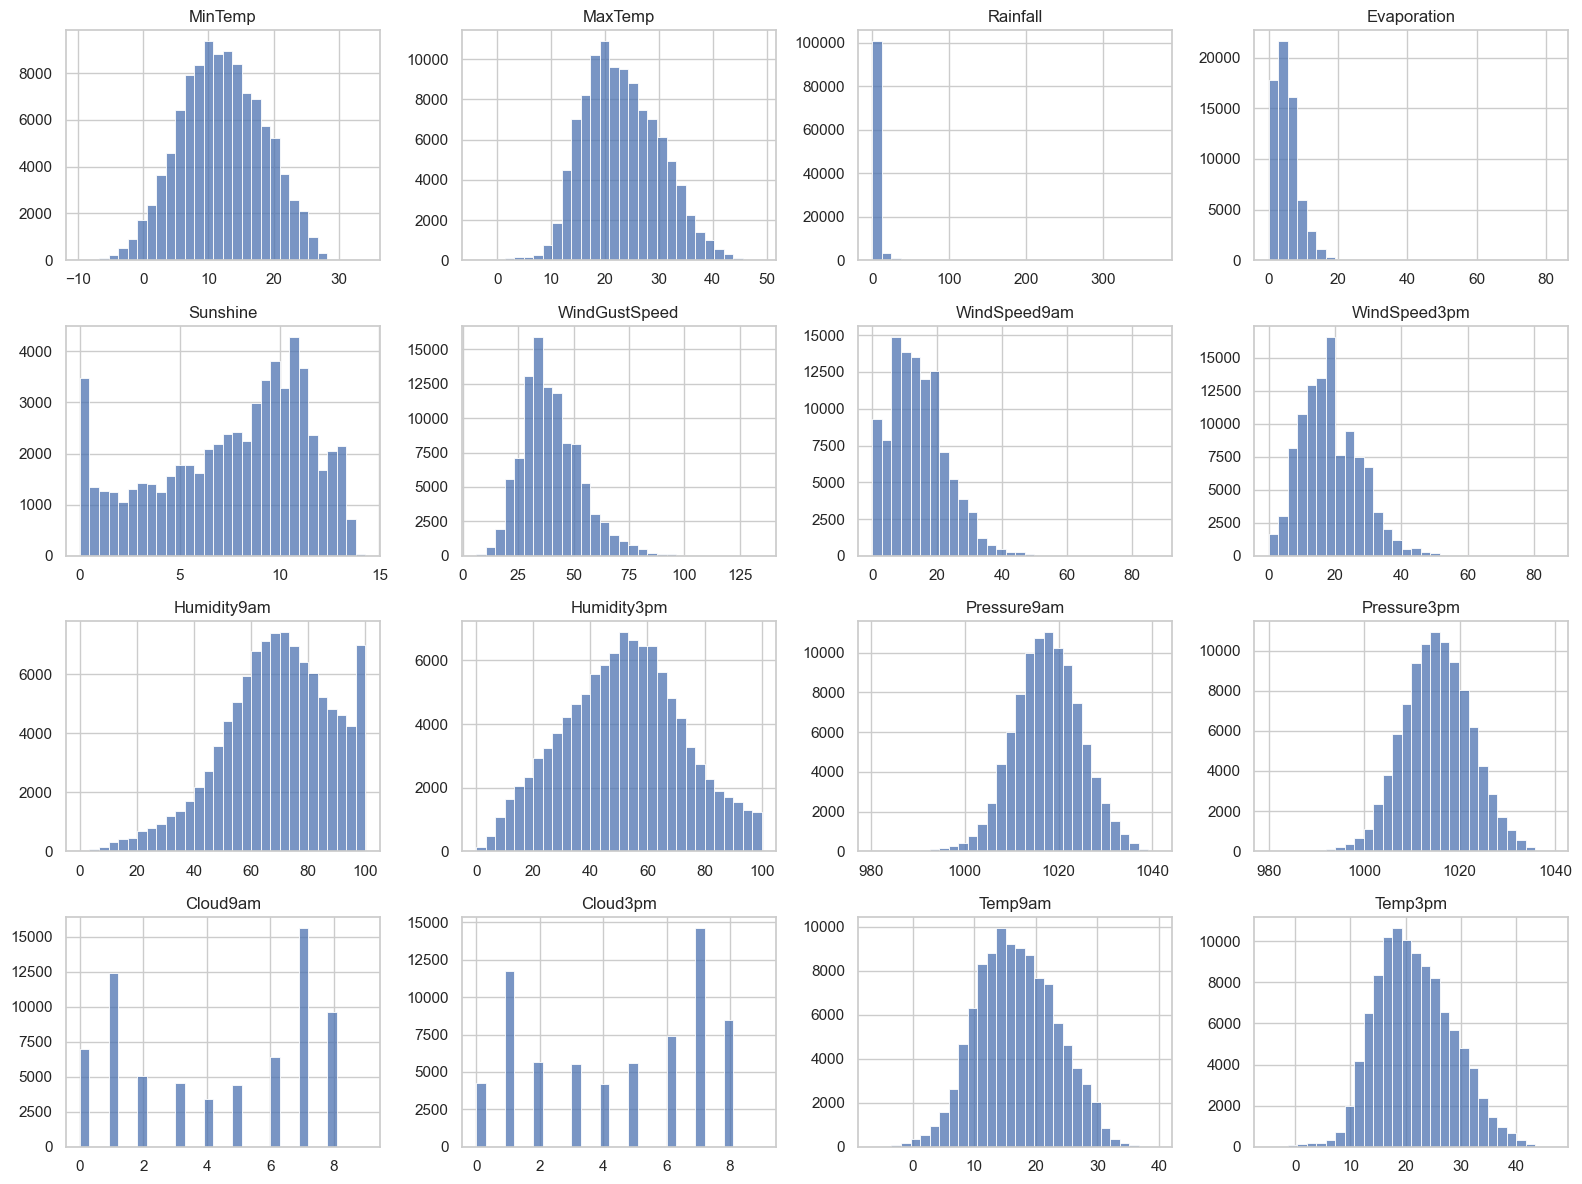

In [9]:
# Un histograma por variable numérica
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, columna in zip(axes.ravel(), numericas):
    sns.histplot(entrenamiento[columna], bins=30, ax=ax)
    ax.set(title=columna, xlabel='', ylabel='')
plt.tight_layout()
plt.show()

- Las temperaturas, las presiones y `Humidity3pm` tienen forma de campana. Las escalas son muy distintas: la
  presión ronda 1015 y la nubosidad va de 0 a 9.
- `Rainfall` y `Evaporation` son muy asimétricas (9.99 y 3.19). La mediana de `Rainfall` es 0.
- La nubosidad solo toma valores enteros.

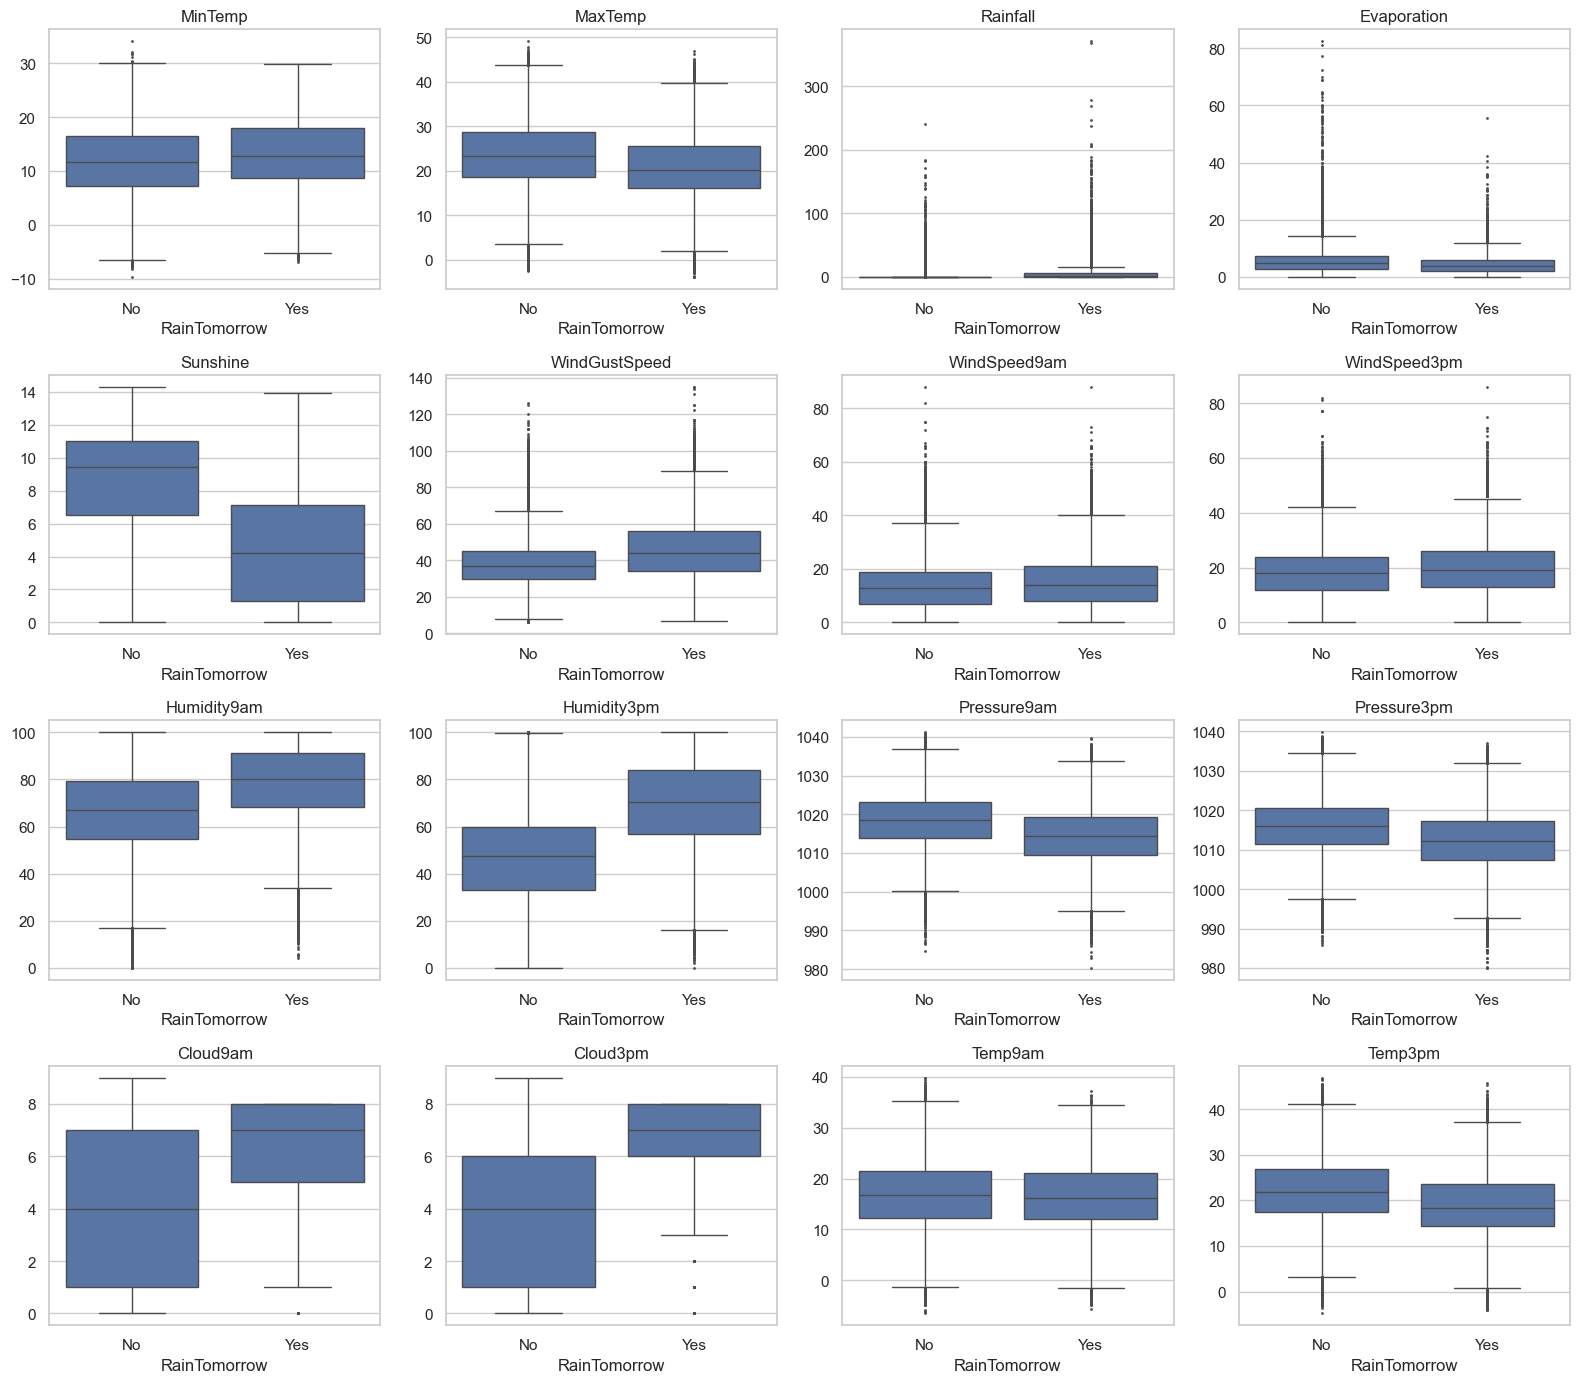

In [10]:
# Diagramas de caja de cada variable según si llueve o no al día siguiente
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, columna in zip(axes.ravel(), numericas):
    sns.boxplot(data=entrenamiento, x='RainTomorrow', y=columna, order=['No', 'Yes'],
                fliersize=1, ax=ax)
    ax.set(title=columna, xlabel='RainTomorrow', ylabel='')
plt.tight_layout()
plt.show()

Las cajas que más se separan entre los días seguidos de lluvia y el resto son las de `Humidity3pm`, `Sunshine`,
`Cloud9am` y `Cloud3pm`. Las temperaturas de la mañana casi no cambian. Hay muchos puntos fuera de los bigotes,
sobre todo en `Rainfall`, `Evaporation` y las velocidades del viento.

In [11]:
# Porcentaje de valores atípicos de cada variable con la regla del rango intercuartílico (IQR)
q1 = entrenamiento[numericas].quantile(0.25)
q3 = entrenamiento[numericas].quantile(0.75)
iqr = q3 - q1
fuera = (entrenamiento[numericas] < q1 - 1.5 * iqr) | (entrenamiento[numericas] > q3 + 1.5 * iqr)
(fuera.sum() / entrenamiento[numericas].notna().sum() * 100).sort_values(ascending=False).round(1)

Rainfall         18.0
Evaporation       2.6
WindGustSpeed     2.3
WindSpeed9am      1.4
WindSpeed3pm      1.2
Humidity9am       1.1
Pressure9am       0.8
Pressure3pm       0.7
Temp3pm           0.6
MaxTemp           0.4
Temp9am           0.2
MinTemp           0.0
Sunshine          0.0
Humidity3pm       0.0
Cloud9am          0.0
Cloud3pm          0.0
dtype: float64

Con la regla del rango intercuartílico (la del notebook de EDA de la cátedra), `Rainfall` tiene 18 % de valores
atípicos y el resto de las variables, menos de 3 %. `Rainfall` la miramos aparte, en los días con lluvia, que son
los de `Rainfall` mayor a 1 según la relación con `RainToday` de la sección 1.1.

Días con Rainfall = 0: 63.3%


count    23861.0
mean        10.4
std         15.8
min          1.1
50%          5.2
90%         23.6
99%         77.5
max        371.0
Name: Rainfall, dtype: float64

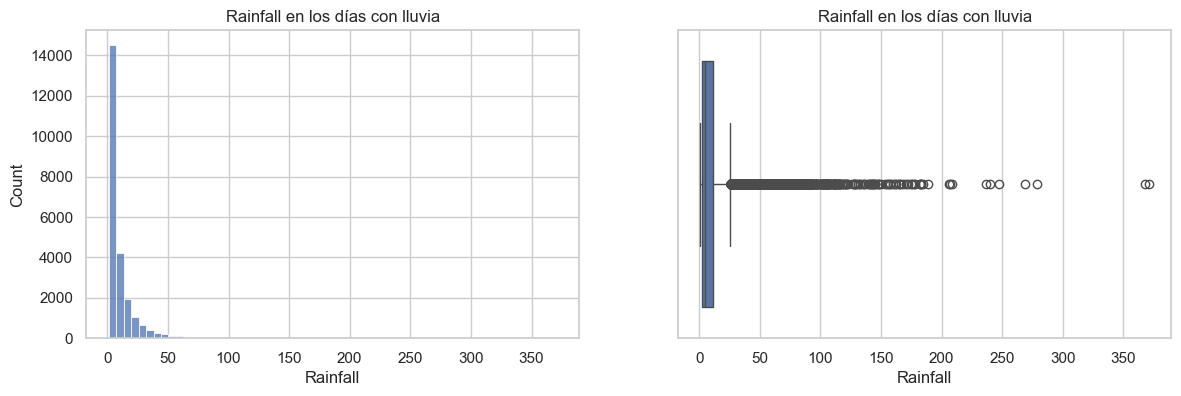

In [12]:
# Rainfall: proporción de días sin lluvia y distribución en los días con lluvia (Rainfall > 1)
lluvia_hoy = entrenamiento['Rainfall']
print(f'Días con Rainfall = 0: {(lluvia_hoy == 0).mean():.1%}')
display(lluvia_hoy[lluvia_hoy > 1].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(lluvia_hoy[lluvia_hoy > 1], bins=60, ax=axes[0])
sns.boxplot(x=lluvia_hoy[lluvia_hoy > 1], ax=axes[1])
axes[0].set(title='Rainfall en los días con lluvia', xlabel='Rainfall')
axes[1].set(title='Rainfall en los días con lluvia', xlabel='Rainfall')
plt.show()

El 63.3 % de los días tiene `Rainfall` igual a 0, así que Q1 y Q3 quedan casi en 0 y la regla marca como atípico
a casi cualquier día con lluvia. En los días con lluvia la distribución es continua y con una cola larga: el 99 %
está por debajo de 77.5 y el máximo es 371. No parecen errores sino lluvias fuertes, y si las sacáramos, el modelo
no aprendería de esos días (apunte de la Unidad 0, sección 4.3).

Conservamos los atípicos y, como recomienda el apunte en ese caso, aplicamos logaritmo a las variables con
asimetría mayor a 1 (sección 1.8).

### 1.4 Variables categóricas y fecha

In [13]:
# Categorías, la más frecuente y su cantidad de filas, para cada variable categórica
entrenamiento[categoricas].describe()

,Location,WindGustDir,WindDir9am,WindDir3pm,RainToday
count,107502,100103,99515,105314,106424
unique,49,16,16,16,2
top,Canberra,W,N,SE,No
freq,2696,7254,8577,8421,82563


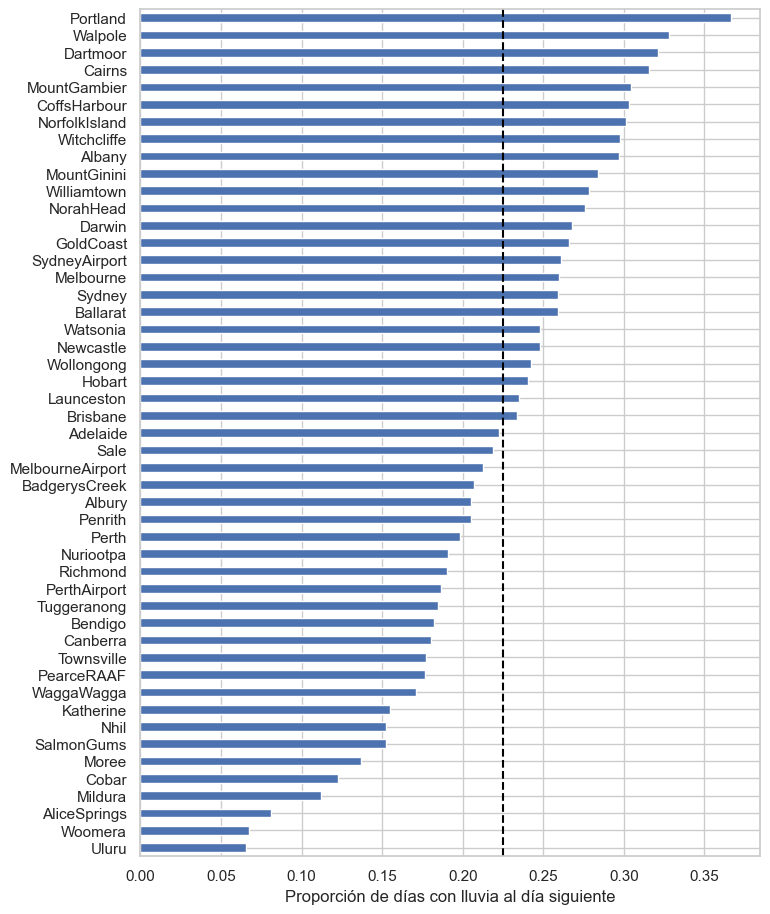

In [14]:
# Proporción de días seguidos de lluvia en cada ciudad (la línea es la proporción general)
lluvia = entrenamiento['RainTomorrow'] == 'Yes'

fig, ax = plt.subplots(figsize=(8, 11))
lluvia.groupby(entrenamiento['Location']).mean().sort_values().plot.barh(ax=ax)
ax.axvline(lluvia.mean(), color='black', linestyle='--')
ax.set(xlabel='Proporción de días con lluvia al día siguiente', ylabel='')
plt.show()

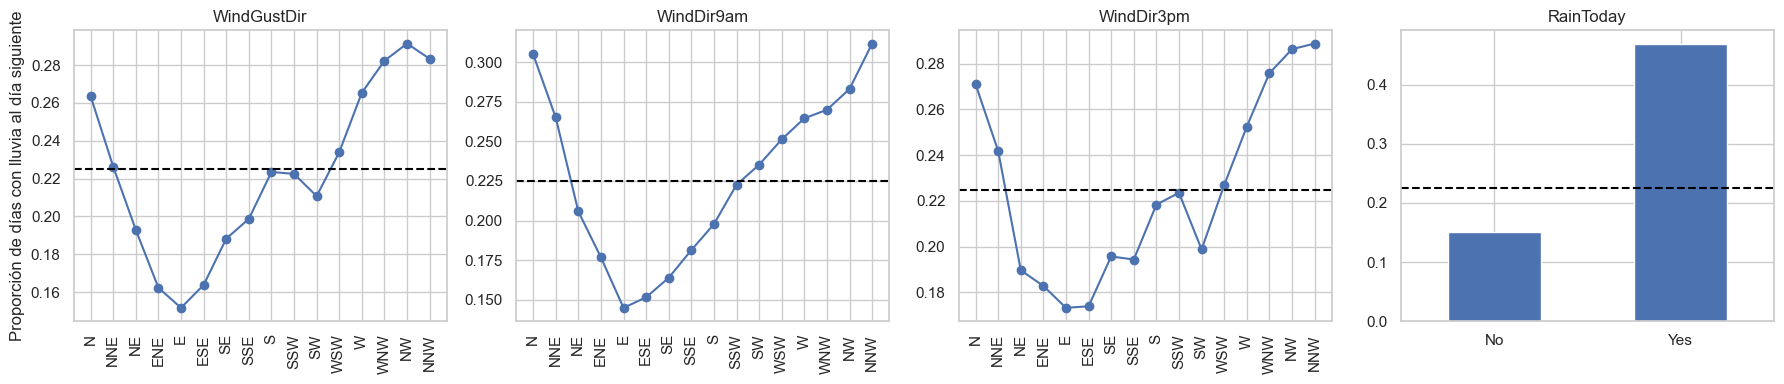

In [15]:
# Lo mismo para las direcciones del viento, en el orden de la brújula, y para RainToday
RUMBOS = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, columna in zip(axes, ['WindGustDir', 'WindDir9am', 'WindDir3pm']):
    proporcion = lluvia.groupby(entrenamiento[columna]).mean().reindex(RUMBOS)
    ax.plot(RUMBOS, proporcion, marker='o')
    ax.set_title(columna)
    ax.tick_params(axis='x', rotation=90)
lluvia.groupby(entrenamiento['RainToday']).mean().plot.bar(ax=axes[3], rot=0)
axes[3].set(title='RainToday', xlabel='')
for ax in axes:
    ax.axhline(lluvia.mean(), color='black', linestyle='--')
axes[0].set_ylabel('Proporción de días con lluvia al día siguiente')
plt.tight_layout()
plt.show()

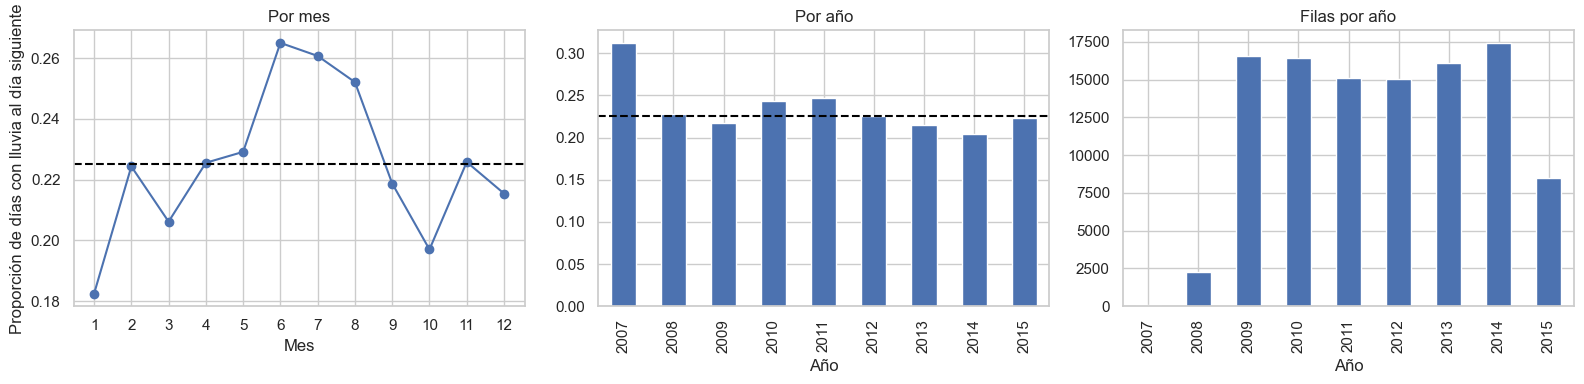

In [16]:
# Proporción de días seguidos de lluvia por mes y por año, y cantidad de filas por año
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
lluvia.groupby(entrenamiento['Date'].dt.month).mean().plot(marker='o', ax=axes[0])
lluvia.groupby(entrenamiento['Date'].dt.year).mean().plot.bar(ax=axes[1])
entrenamiento['Date'].dt.year.value_counts().sort_index().plot.bar(ax=axes[2])
for ax in axes[:2]:
    ax.axhline(lluvia.mean(), color='black', linestyle='--')
axes[0].set(title='Por mes', xlabel='Mes', xticks=range(1, 13),
            ylabel='Proporción de días con lluvia al día siguiente')
axes[1].set(title='Por año', xlabel='Año')
axes[2].set(title='Filas por año', xlabel='Año')
plt.tight_layout()
plt.show()

- `Location`: la proporción de días seguidos de lluvia va de menos del 10 % a más del 35 % según la ciudad.
- Direcciones del viento: en el orden de la brújula, la proporción cambia de forma continua, con un máximo entre NW
  y N y un mínimo cerca de E. Los rumbos vecinos se parecen, incluido el último (NNW) con el primero (N).
- `RainToday`: después de un día con lluvia, llueve al día siguiente en cerca del 47 % de los casos, contra el 15 %
  después de un día sin lluvia.
- Mes: la proporción sube a mitad de año (junio a agosto, alrededor del 26 %) y es mínima en enero (18 %).
- Año: entre 2008 y 2015 queda entre 20 % y 25 %; 2007 tiene muy pocas filas. No usamos el año como variable,
  porque el modelo siempre va a predecir años que no vio.

Todas se relacionan con la lluvia, así que las usamos. Las direcciones y el mes son cíclicos, y para ellos usamos la
codificación cíclica del apunte de la Unidad 0 (sección 5.3.9): el seno y el coseno del valor. Así los valores
vecinos quedan cerca (NNW y N, diciembre y enero), con dos columnas en lugar de las 15 u 11 del one-hot.
`Location` y `RainToday` van con one-hot (sección 1.8).

### 1.5 Datos faltantes

In [17]:
# Porcentaje de faltantes de cada variable
faltantes = entrenamiento.isna().mean().sort_values(ascending=False) * 100
faltantes[faltantes > 0].round(1)

Sunshine         42.0
Evaporation      38.4
Cloud3pm         37.2
Cloud9am         36.3
Pressure9am       9.6
Pressure3pm       9.5
WindDir9am        7.4
WindGustDir       6.9
WindGustSpeed     6.8
WindDir3pm        2.0
Humidity9am       1.3
Humidity3pm       1.2
WindSpeed3pm      1.1
WindSpeed9am      1.1
RainToday         1.0
Rainfall          1.0
Temp9am           0.7
Temp3pm           0.6
MinTemp           0.4
MaxTemp           0.2
dtype: float64

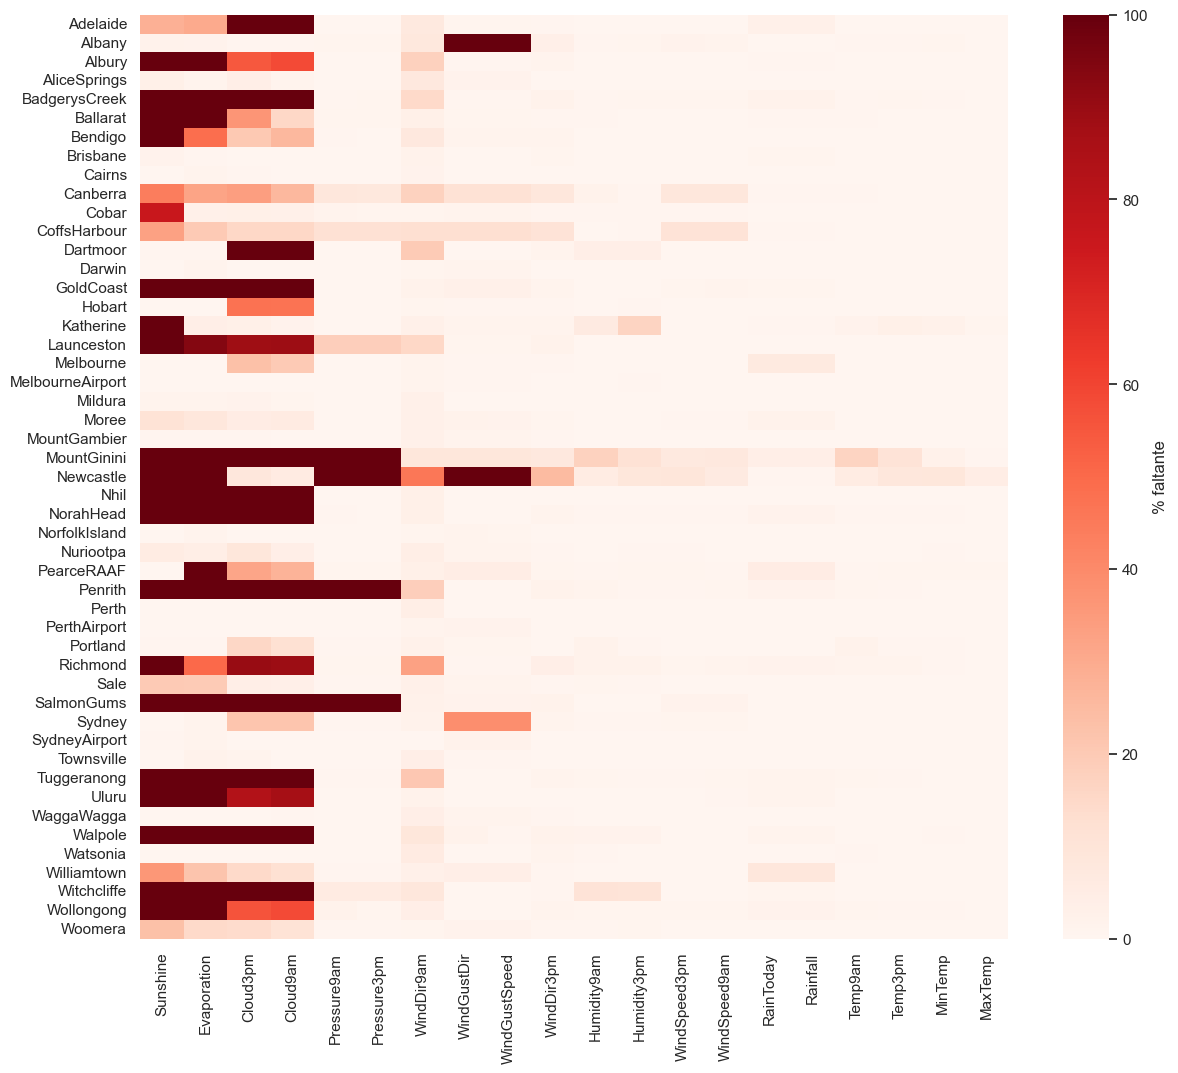

In [18]:
# Porcentaje de faltantes de cada variable en cada ciudad
con_faltantes = faltantes[faltantes > 0].index
plt.figure(figsize=(14, 12))
sns.heatmap(entrenamiento[con_faltantes].isna().groupby(entrenamiento['Location']).mean() * 100,
            cmap='Reds', cbar_kws={'label': '% faltante'})
plt.xlabel('')
plt.ylabel('')
plt.show()

`Sunshine`, `Evaporation`, `Cloud3pm` y `Cloud9am` tienen entre 36 % y 42 % de faltantes; el resto, menos de 10 %. El
mapa muestra que los faltantes dependen de la ciudad: varias ciudades no tienen ningún dato de alguna variable, y
otras casi no tienen faltantes. No faltan completamente al azar, sino según una variable observada, la ciudad (MAR,
en los términos del apunte de la Unidad 0).

Decisiones:

- Numéricas: la mediana de la misma ciudad, calculada en entrenamiento, como propone el apunte (sección 3.2.4). Si
  la ciudad no tiene ningún dato de esa variable, la mediana general. No usamos `KNNImputer` por el tiempo de
  procesamiento: compara cada fila con faltantes contra las más de 100.000 de entrenamiento.
- Las cuatro variables con más faltantes se conservan: en los diagramas de caja están entre las que más separan las
  clases, y en su notebook de imputación la cátedra descarta una variable recién cuando le falta el 77 %.
- `RainToday`: la moda. Las direcciones del viento se imputan como numéricas, después de pasarlas a seno y coseno.

### 1.6 Balance de clases

In [19]:
# Cantidad de días con y sin lluvia al día siguiente
conteo = entrenamiento['RainTomorrow'].value_counts()
print(conteo)
print(f"Días con lluvia: {conteo['Yes'] / conteo.sum():.1%}")
print(f"Relación de desbalance (No / Yes): {conteo['No'] / conteo['Yes']:.1f}")

RainTomorrow
No     83320
Yes    24182
Name: count, dtype: int64
Días con lluvia: 22.5%
Relación de desbalance (No / Yes): 3.4


El 22.5 % de los días está seguido de un día de lluvia: hay 3.4 días sin lluvia por cada uno con lluvia. La clase
minoritaria tiene el 29 % de las observaciones de la mayoritaria, así que, con el criterio del notebook de EDA de la
cátedra (entre 20 % y 40 %), el dataset está moderadamente desbalanceado.

Importa por dos motivos: un modelo que diga siempre "no llueve" acertaría el 77.5 % de las veces sin aprender nada,
y al minimizar el error total el modelo tiende a favorecer a la clase mayoritaria (clase 9). Por eso en el ítem 2
usamos `class_weight='balanced'` y métricas de la clase "llueve".

### 1.7 Matriz de correlación

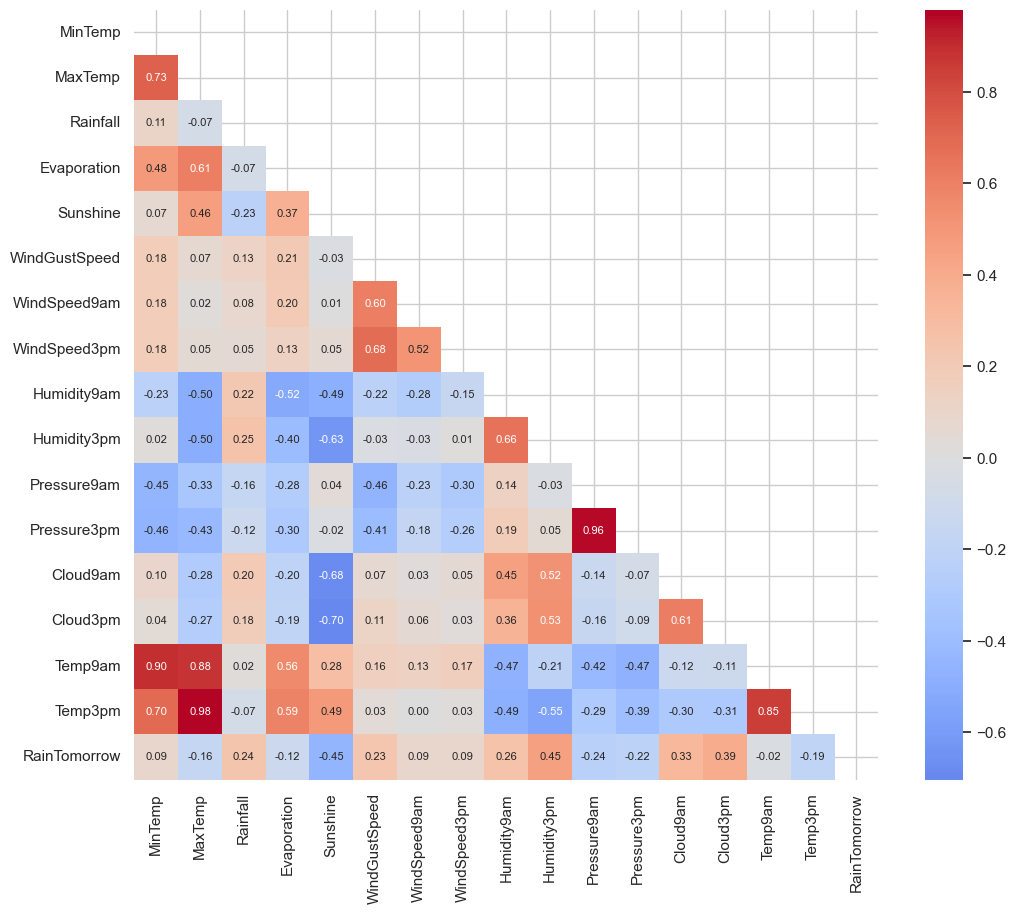

In [20]:
# Correlación entre las variables numéricas y con la variable objetivo (0/1)
correlacion = entrenamiento[numericas].assign(RainTomorrow=y_train).corr()
triangulo_superior = np.triu(np.ones(correlacion.shape, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(correlacion, mask=triangulo_superior, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, annot_kws={'size': 8})
plt.show()

In [21]:
# Pares de variables con correlación de 0.85 o más (umbral del notebook de EDA de la cátedra)
for i, a in enumerate(numericas):
    for b in numericas[i + 1:]:
        if abs(correlacion.loc[a, b]) >= 0.85:
            print(f'{a} y {b}: {correlacion.loc[a, b]:.2f}')

MinTemp y Temp9am: 0.90
MaxTemp y Temp9am: 0.88
MaxTemp y Temp3pm: 0.98
Pressure9am y Pressure3pm: 0.96
Temp9am y Temp3pm: 0.85


Con la variable objetivo (última fila), las correlaciones más fuertes son las de `Humidity3pm` (0.45), `Sunshine`
(−0.45), `Cloud3pm` (0.39) y `Cloud9am` (0.33). Hay cinco pares con correlación de 0.85 o más, todos entre
temperaturas o entre presiones.

Los dejamos: sacar una de ellas puede hacer perder la información que no comparte con la otra (apunte de la Unidad
0, sección 5.4, y notebook `correlacion.ipynb`), y la regularización L2 de la regresión logística reparte el peso
entre variables correlacionadas (clase 5).

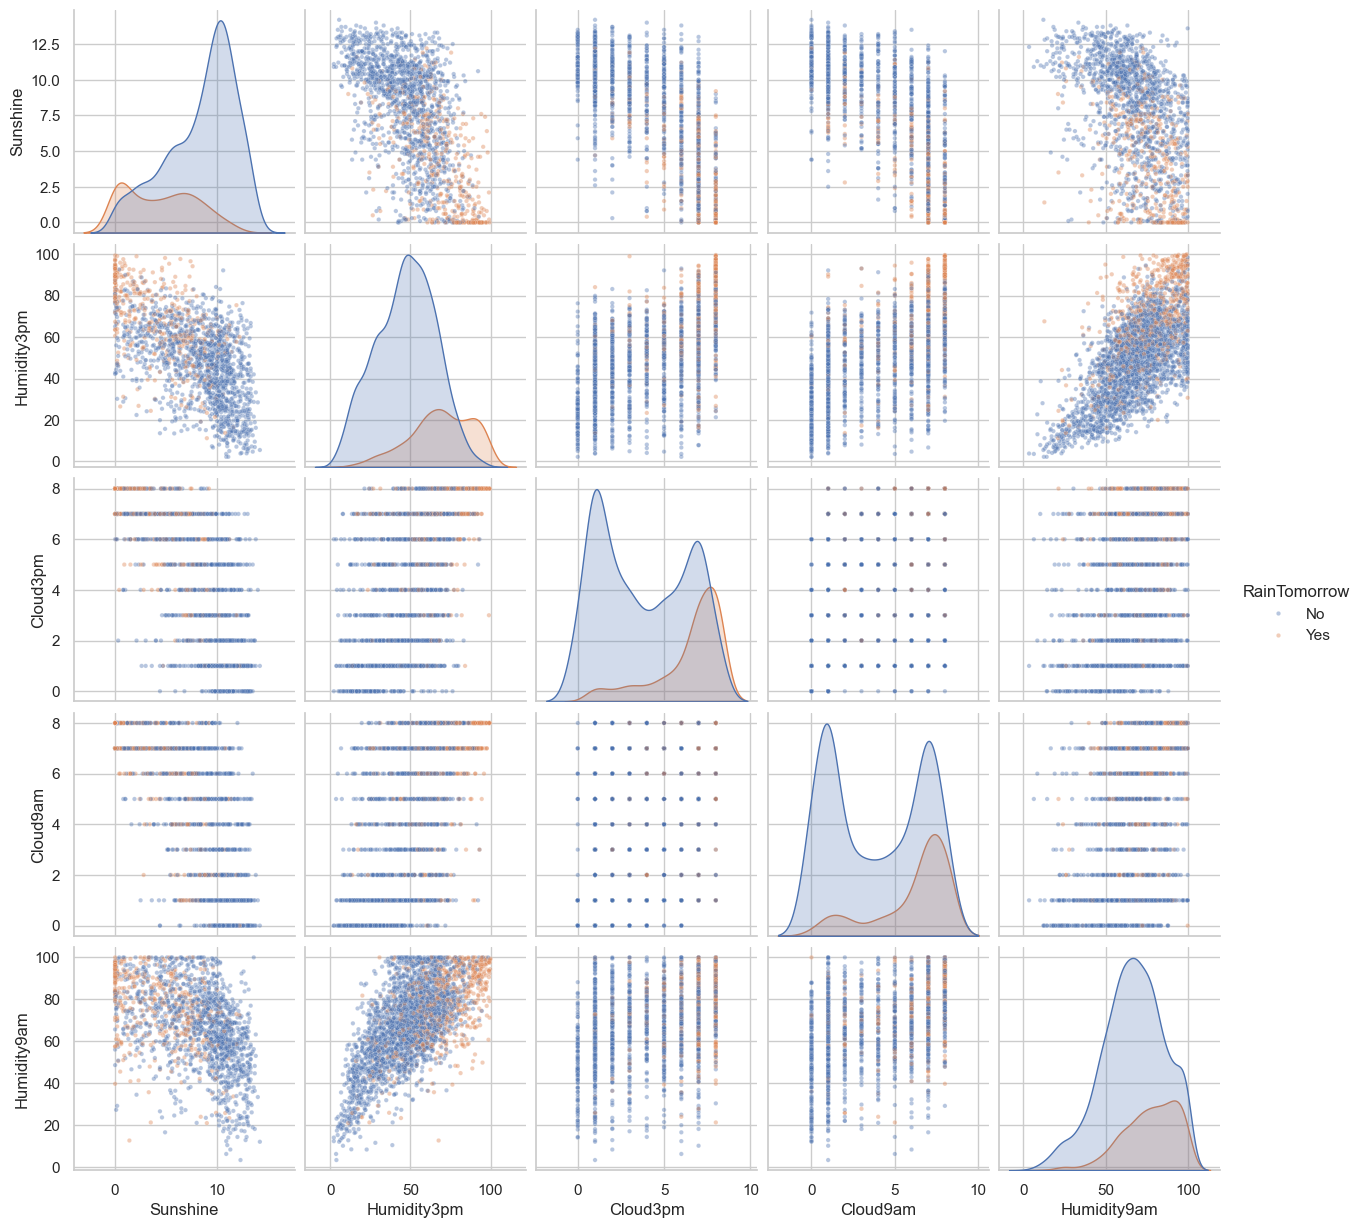

In [22]:
# Pairplot de las cinco variables más correlacionadas con la variable objetivo, sobre una muestra
mas_correlacionadas = correlacion['RainTomorrow'].drop('RainTomorrow').abs().nlargest(5).index.tolist()
muestra = entrenamiento.sample(3000, random_state=SEMILLA)
sns.pairplot(muestra, vars=mas_correlacionadas, hue='RainTomorrow', hue_order=['No', 'Yes'],
             plot_kws={'alpha': 0.4, 's': 10})
plt.show()

En las cinco variables más correlacionadas con la variable objetivo, los días seguidos de lluvia (naranja) se
concentran con poco sol, humedad alta y mucha nubosidad. Pero las clases se superponen en todos los pares: ninguna
combinación de dos variables las separa.

### 1.8 Preparación de los datos: codificación, imputación y escalado

Aplicamos las decisiones anteriores, en este orden:

1. Codificación cíclica de las direcciones del viento y del mes.
2. Imputación de las numéricas con la mediana de cada ciudad.
3. Logaritmo de las variables con asimetría mayor a 1.
4. Escalado de las numéricas y one-hot de las categóricas.

Los pasos 1 y 3 son fórmulas fijas que no aprenden nada de los datos, así que se aplican igual a los tres
conjuntos. Los pasos 2 y 4 se calculan solo con entrenamiento.

In [23]:
# Codificación cíclica: seno y coseno de 2π·valor/n (N = 1, ..., NNW = 16 y enero = 1, ..., diciembre = 12)
direcciones = ['WindGustDir', 'WindDir9am', 'WindDir3pm']
numero_rumbo = {rumbo: i + 1 for i, rumbo in enumerate(RUMBOS)}

for X, conjunto in [(X_train, entrenamiento), (X_val, validacion), (X_test, prueba)]:
    for columna in direcciones:
        valor = X[columna].map(numero_rumbo)
        X[columna + '_sin'] = np.sin(2 * np.pi * valor / 16)
        X[columna + '_cos'] = np.cos(2 * np.pi * valor / 16)
    mes = conjunto['Date'].dt.month
    X['Mes_sin'] = np.sin(2 * np.pi * mes / 12)
    X['Mes_cos'] = np.cos(2 * np.pi * mes / 12)
    X.drop(columns=direcciones, inplace=True)

# Las columnas nuevas son numéricas; como categóricas quedan Location y RainToday
numericas = numericas + ['WindGustDir_sin', 'WindGustDir_cos', 'WindDir9am_sin', 'WindDir9am_cos',
                         'WindDir3pm_sin', 'WindDir3pm_cos', 'Mes_sin', 'Mes_cos']
categoricas = ['Location', 'RainToday']
X_train[numericas[-8:]].describe().round(2)

,WindGustDir_sin,WindGustDir_cos,WindDir9am_sin,WindDir9am_cos,WindDir3pm_sin,WindDir3pm_cos,Mes_sin,Mes_cos
count,100103.00,100103.00,99515.00,99515.00,105314.00,105314.00,107502.00,107502.00
mean,-0.04,-0.04,0.02,0.00,-0.03,-0.04,0.02,-0.02
std,0.71,0.70,0.69,0.72,0.70,0.71,0.70,0.71
min,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00
25%,-0.71,-0.71,-0.71,-0.71,-0.71,-0.71,-0.50,-0.87
50%,-0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,-0.00
75%,0.71,0.71,0.71,0.71,0.71,0.71,0.50,0.50
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [24]:
# Imputación de las numéricas con la mediana de su ciudad, calculada en entrenamiento.
# Si la ciudad no tiene ningún dato de esa variable, con la mediana general
medianas_ciudad = X_train.groupby('Location')[numericas].median()
medianas_generales = X_train[numericas].median()

for X in [X_train, X_val, X_test]:
    for columna in numericas:
        X[columna] = X[columna].fillna(X['Location'].map(medianas_ciudad[columna]))
        X[columna] = X[columna].fillna(medianas_generales[columna])

print('Faltantes en las numéricas:', X_train[numericas].isna().sum().sum(),
      X_val[numericas].isna().sum().sum(), X_test[numericas].isna().sum().sum())

Faltantes en las numéricas: 0 0 0


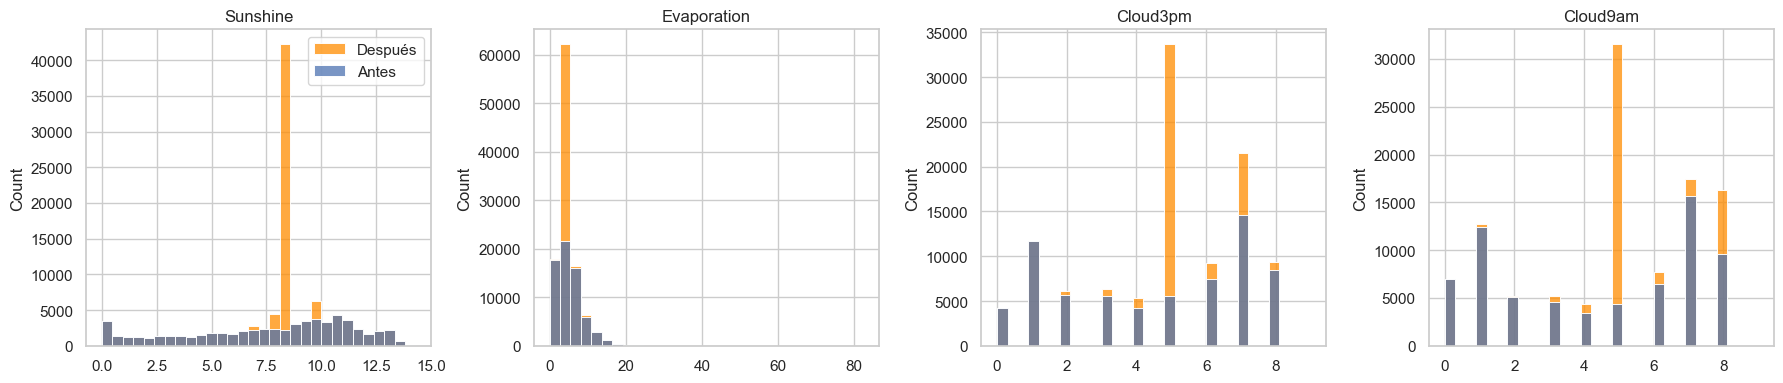

In [25]:
# Distribución antes y después de imputar, en las cuatro variables con más faltantes
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, columna in zip(axes, faltantes.index[:4]):
    sns.histplot(X_train[columna], bins=30, color='darkorange', label='Después', ax=ax)
    sns.histplot(entrenamiento[columna], bins=30, label='Antes', ax=ax)
    ax.set(title=columna, xlabel='')
axes[0].legend()
plt.tight_layout()
plt.show()

Cada faltante tomó la mediana de su ciudad. El pico de cada histograma corresponde a las ciudades que nunca miden
esa variable, que reciben la mediana general: para esas ciudades, la variable no aporta información.

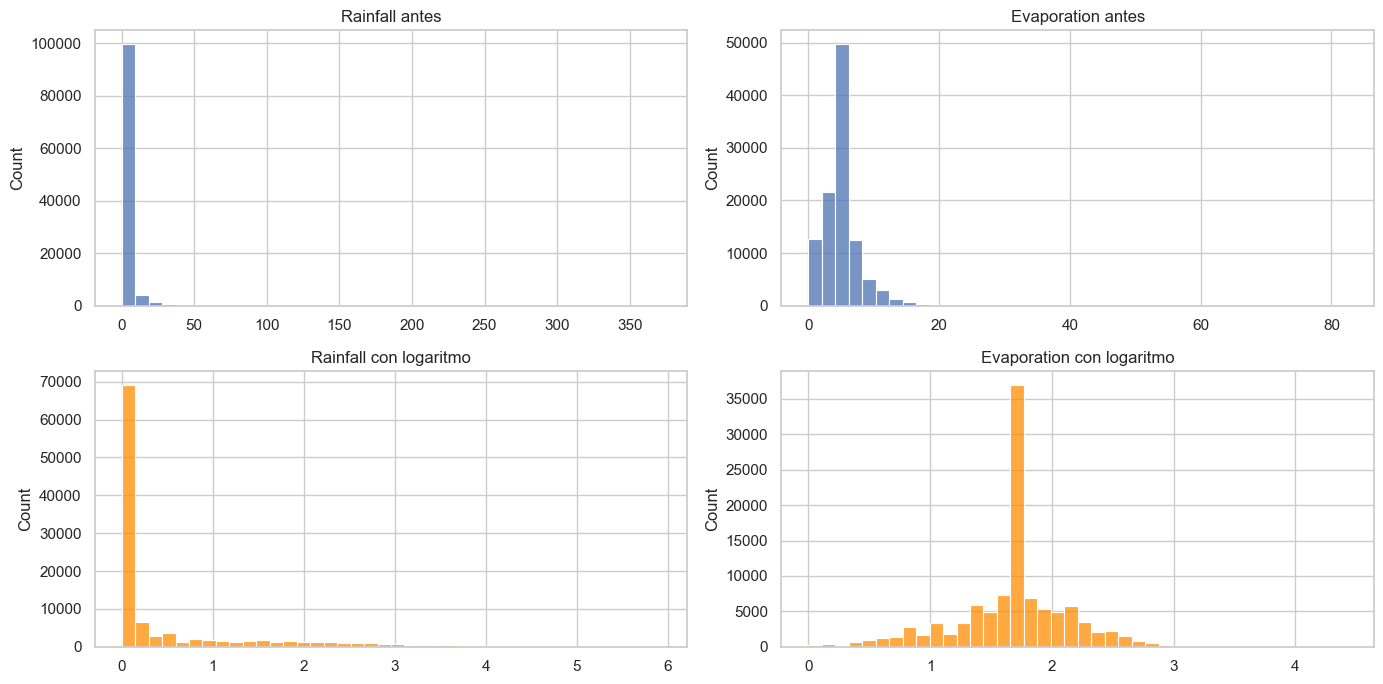

,Asimetría antes,Asimetría después,Máximo antes,Máximo después
Rainfall,10.04,2.06,371.0,5.92
Evaporation,4.17,-0.33,82.4,4.42


In [26]:
# Logaritmo, log(x + 1), de las variables con asimetría mayor a 1 (tabla de la sección 1.3)
asimetricas = resumen.index[resumen['Asimetría'] > 1].tolist()
antes = X_train[asimetricas].copy()
for X in [X_train, X_val, X_test]:
    X[asimetricas] = np.log1p(X[asimetricas])

fig, axes = plt.subplots(2, len(asimetricas), figsize=(14, 7))
for j, columna in enumerate(asimetricas):
    sns.histplot(antes[columna], bins=40, ax=axes[0, j])
    sns.histplot(X_train[columna], bins=40, color='darkorange', ax=axes[1, j])
    axes[0, j].set(title=f'{columna} antes', xlabel='')
    axes[1, j].set(title=f'{columna} con logaritmo', xlabel='')
plt.tight_layout()
plt.show()

pd.DataFrame({'Asimetría antes': antes.skew(), 'Asimetría después': X_train[asimetricas].skew(),
              'Máximo antes': antes.max(), 'Máximo después': X_train[asimetricas].max()}).round(2)

Con el logaritmo, la asimetría de `Rainfall` baja de 10.04 a 2.06 y la de `Evaporation`, de 4.17 a −0.33. Los
valores extremos quedan mucho más cerca del resto: el máximo de `Rainfall` pasa de 371 a 5.92.

In [27]:
# Escalado de las numéricas y one-hot de las categóricas, cada uno con su lista de columnas
preprocesador = ColumnTransformer([
    ('num', StandardScaler(), numericas),
    ('cat', Pipeline([('imputador', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(drop='if_binary', handle_unknown='ignore',
                                               sparse_output=False))]), categoricas),
])
preprocesador.set_output(transform='pandas')

# Se ajusta solo con entrenamiento; validación y prueba se transforman con lo aprendido ahí
X_train_prep = preprocesador.fit_transform(X_train)
X_val_prep = preprocesador.transform(X_val)
X_test_prep = preprocesador.transform(X_test)
X_train_prep.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
Index: 107502 entries, 45573 to 123065
Data columns (total 74 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   num__MinTemp                    107502 non-null  float64
 1   num__MaxTemp                    107502 non-null  float64
 2   num__Rainfall                   107502 non-null  float64
 3   num__Evaporation                107502 non-null  float64
 4   num__Sunshine                   107502 non-null  float64
 5   num__WindGustSpeed              107502 non-null  float64
 6   num__WindSpeed9am               107502 non-null  float64
 7   num__WindSpeed3pm               107502 non-null  float64
 8   num__Humidity9am                107502 non-null  float64
 9   num__Humidity3pm                107502 non-null  float64
 10  num__Pressure9am                107502 non-null  float64
 11  num__Pressure3pm                107502 non-null  float64
 12  num__Cloud9am    

In [28]:
# Faltantes que quedan en cada conjunto, y media y desvío de las numéricas ya escaladas
print('Faltantes:', X_train_prep.isna().sum().sum(), X_val_prep.isna().sum().sum(), X_test_prep.isna().sum().sum())
X_train_prep.filter(like='num__').describe().round(2)

Faltantes: 0 0 0


,num__MinTemp,num__MaxTemp,num__Rainfall,num__Evaporation,num__Sunshine,num__WindGustSpeed,num__WindSpeed9am,num__WindSpeed3pm,num__Humidity9am,num__Humidity3pm,...,num__Temp9am,num__Temp3pm,num__WindGustDir_sin,num__WindGustDir_cos,num__WindDir9am_sin,num__WindDir9am_cos,num__WindDir3pm_sin,num__WindDir3pm_cos,num__Mes_sin,num__Mes_cos
count,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,...,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00
mean,0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,...,0.00,0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.42,-3.84,-0.53,-3.59,-2.72,-2.57,-1.57,-2.10,-3.63,-2.49,...,-3.62,-3.84,-1.41,-1.41,-1.50,-1.44,-1.39,-1.35,-1.44,-1.38
25%,-0.71,-0.74,-0.53,-0.35,-0.16,-0.68,-0.79,-0.75,-0.62,-0.71,...,-0.72,-0.73,-0.98,-0.98,-1.07,-1.02,-0.97,-0.94,-0.73,-1.19
50%,-0.03,-0.08,-0.53,0.07,0.15,-0.15,-0.12,-0.08,0.06,0.02,...,-0.04,-0.09,0.05,0.06,-0.02,-0.01,0.04,0.06,-0.02,0.03
75%,0.72,0.70,-0.02,0.42,0.53,0.53,0.55,0.60,0.75,0.68,...,0.70,0.67,1.08,1.09,1.03,1.00,1.06,1.06,0.69,0.73
max,3.45,3.70,6.00,5.82,2.17,7.17,8.25,7.57,1.64,2.34,...,3.56,3.68,1.51,1.52,1.46,1.42,1.47,1.48,1.40,1.44


El `ColumnTransformer` aplica a cada lista de columnas su propio paso: `StandardScaler` a las de `numericas`
(prefijo `num__`) y one-hot a las de `categoricas` (prefijo `cat__`).

- `StandardScaler` deja cada numérica con media 0 y desvío 1, calculados en entrenamiento. Escalamos porque las
  escalas son muy distintas y la regularización castiga el tamaño de los coeficientes (apunte, sección 5.1.1).
- One-hot: `Location` conserva sus 49 columnas, porque en uso real puede aparecer una ciudad nueva, que queda con
  todas en 0 (`handle_unknown='ignore'`; apunte, secciones 5.3.2 y 5.3.3). `RainToday`, que tiene dos categorías,
  queda en una sola columna 0/1 (`drop='if_binary'`).

Quedan 74 columnas (24 numéricas, 49 de `Location` y 1 de `RainToday`), sin faltantes en ninguno de los tres
conjuntos.

## 2. Regresión logística

Usamos `class_weight='balanced'`, que pesa los errores de cada clase según la inversa de su frecuencia: con el
desbalance de la sección 1.6, equivocarse en un día de lluvia cuesta 3.4 veces más que en uno sin lluvia (clase 9).
El modelo va en el mismo pipeline que el escalado y el one-hot.

In [29]:
# El preprocesamiento del ítem 1 y la regresión logística, en un solo pipeline
modelo = Pipeline([
    ('preprocesamiento', preprocesador),
    ('clasificador', LogisticRegression(class_weight='balanced')),
])
modelo.fit(X_train, y_train)

# Probabilidad de lluvia que da el modelo en validación y en prueba
prob_val = modelo.predict_proba(X_val)[:, 1]
prob_test = modelo.predict_proba(X_test)[:, 1]

### 2.1 Métricas y matrices de confusión

La clase positiva es "llueve" (1).

- Accuracy: proporción de aciertos. Con clases desbalanceadas engaña (sección 1.6).
- Precisión: de los días en que el modelo anuncia lluvia, en cuántos llovió.
- Recall: de los días en que llovió, cuántos detectó.
- F1: media armónica de precisión y recall.
- Adicionales: la accuracy balanceada (promedio del recall de las dos clases) y el área bajo la curva
  precisión-recall. Como el AUC ROC, esa área no depende del umbral, pero mira solo la clase "llueve", así que es
  más exigente cuando esa clase es la minoritaria.

La métrica principal es el F1 de "llueve": nos importan los dos errores, y la clase 8 la recomienda para datos
desbalanceados.

In [30]:
def metricas(y_real, prob, umbral=0.5):
    """Calcula las métricas, prediciendo lluvia cuando la probabilidad llega al umbral."""
    y_pred = (prob >= umbral).astype(int)
    return {
        'Accuracy': accuracy_score(y_real, y_pred),
        'Accuracy balanceada': balanced_accuracy_score(y_real, y_pred),
        'Precisión': precision_score(y_real, y_pred, zero_division=0),
        'Recall': recall_score(y_real, y_pred),
        'F1': f1_score(y_real, y_pred),
        'AUC ROC': roc_auc_score(y_real, prob),
        'AUC precisión-recall': average_precision_score(y_real, prob),
    }


# Métricas en prueba con el umbral por defecto (0.5)
pd.Series(metricas(y_test, prob_test)).round(3)

Accuracy                0.790
Accuracy balanceada     0.775
Precisión               0.533
Recall                  0.747
F1                      0.622
AUC ROC                 0.858
AUC precisión-recall    0.693
dtype: float64

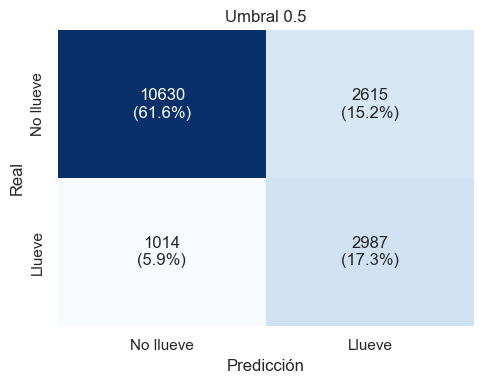

In [31]:
CLASES = ['No llueve', 'Llueve']


def graficar_matrices(y_real, predicciones):
    """Grafica una matriz de confusión por modelo, con la cantidad y el porcentaje sobre el total."""
    fig, axes = plt.subplots(1, len(predicciones), figsize=(5 * len(predicciones), 4), squeeze=False)
    for ax, (nombre, y_pred) in zip(axes[0], predicciones.items()):
        matriz = confusion_matrix(y_real, y_pred)
        etiquetas = [[f'{n}\n({n / matriz.sum():.1%})' for n in fila] for fila in matriz]
        sns.heatmap(matriz, annot=etiquetas, fmt='', cmap='Blues', cbar=False,
                    xticklabels=CLASES, yticklabels=CLASES, ax=ax)
        ax.set(title=nombre, xlabel='Predicción', ylabel='Real')
    plt.tight_layout()
    plt.show()


graficar_matrices(y_test, {'Umbral 0.5': (prob_test >= 0.5).astype(int)})

Con umbral 0.5, el modelo detecta el 74.7 % de los días con lluvia (recall), pero solo el 53.3 % de sus avisos son
correctos (precisión). Hay 2615 falsas alarmas (15.2 % de los días) y 1014 lluvias sin avisar (5.9 %).

- Falso positivo: anuncia lluvia y no llueve. Por ejemplo, alguien suspende una actividad sin necesidad.
- Falso negativo: no anuncia lluvia y llueve. Alguien queda expuesto sin estar preparado.

### 2.2 Curva ROC y umbral de decisión

El modelo da una probabilidad y predice lluvia cuando llega al umbral. El 0.5 es el valor por defecto, pero no
tiene por qué ser el mejor (clase 7). Elegimos el umbral en validación, donde se cruzan la precisión y el recall:
el punto que no favorece a ninguno de los dos errores.

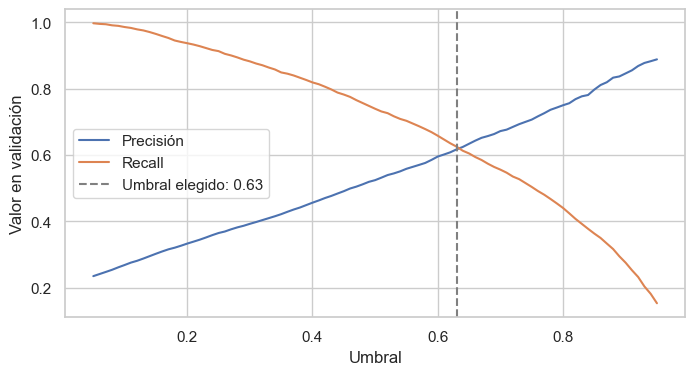

In [32]:
# Precisión y recall en validación para cada umbral entre 0.05 y 0.95
umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
precisiones = np.array([precision_score(y_val, (prob_val >= u).astype(int), zero_division=0)
                        for u in umbrales])
recalls = np.array([recall_score(y_val, (prob_val >= u).astype(int)) for u in umbrales])

# Elegimos el umbral donde se cruzan las dos curvas
umbral = umbrales[np.argmin(np.abs(precisiones - recalls))]

plt.figure(figsize=(8, 4))
plt.plot(umbrales, precisiones, label='Precisión')
plt.plot(umbrales, recalls, label='Recall')
plt.axvline(umbral, color='gray', linestyle='--', label=f'Umbral elegido: {umbral:.2f}')
plt.xlabel('Umbral')
plt.ylabel('Valor en validación')
plt.legend()
plt.show()

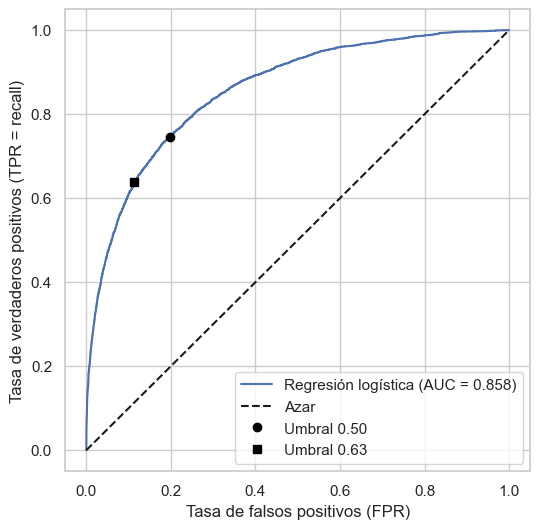

In [33]:
# Curva ROC en prueba, con el punto que corresponde a cada umbral
fpr, tpr, _ = roc_curve(y_test, prob_test)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Regresión logística (AUC = {roc_auc_score(y_test, prob_test):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
for u, marcador in [(0.5, 'o'), (umbral, 's')]:
    tn, fp, fn, tp = confusion_matrix(y_test, (prob_test >= u).astype(int)).ravel()
    plt.plot(fp / (fp + tn), tp / (tp + fn), marcador, color='black', label=f'Umbral {u:.2f}')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR = recall)')
plt.legend(loc='lower right')
plt.show()

,Accuracy,Accuracy balanceada,Precisión,Recall,F1,AUC ROC,AUC precisión-recall
Umbral 0.5,0.790,0.775,0.533,0.747,0.622,0.858,0.693
Umbral 0.63,0.829,0.762,0.629,0.638,0.634,0.858,0.693


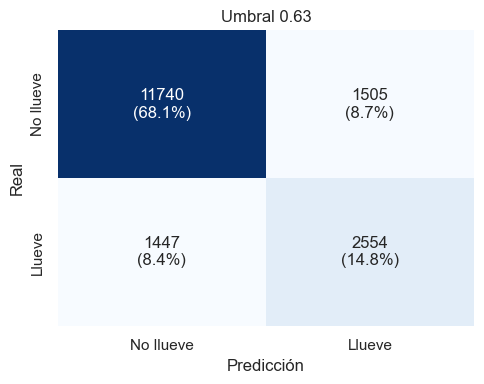

In [34]:
# Métricas en prueba con el umbral 0.5 y con el elegido en validación
display(pd.DataFrame({'Umbral 0.5': metricas(y_test, prob_test),
                      f'Umbral {umbral:.2f}': metricas(y_test, prob_test, umbral)}).T.round(3))

graficar_matrices(y_test, {f'Umbral {umbral:.2f}': (prob_test >= umbral).astype(int)})

- ¿Es 0.5 el mejor umbral? Para nuestro criterio, no: con 0.5 el modelo favorece el recall a costa de muchas
  falsas alarmas. Con 0.63, en prueba, la precisión sube de 0.533 a 0.629 y el recall baja de 0.747 a 0.638; el F1
  mejora de 0.622 a 0.634, y las falsas alarmas bajan de 2615 a 1505.
- En la curva ROC, subir el umbral mueve el punto hacia abajo y a la izquierda: menos falsas alarmas y menos lluvias
  detectadas. El AUC (0.858) es el mismo para cualquier umbral.
- El umbral adecuado depende de cuánto cuesta cada error. Si no avisar una lluvia fuera mucho más grave que una
  falsa alarma, convendría uno más bajo.

### 2.3 ¿Conseguimos un buen ajuste?

In [35]:
# Mismas métricas en los tres conjuntos, con el umbral elegido
pd.DataFrame({'Entrenamiento': metricas(y_train, modelo.predict_proba(X_train)[:, 1], umbral),
              'Validación': metricas(y_val, prob_val, umbral),
              'Prueba': metricas(y_test, prob_test, umbral)}).T.round(3)

,Accuracy,Accuracy balanceada,Precisión,Recall,F1,AUC ROC,AUC precisión-recall
Entrenamiento,0.832,0.776,0.615,0.673,0.643,0.874,0.708
Validación,0.838,0.760,0.617,0.625,0.621,0.865,0.675
Prueba,0.829,0.762,0.629,0.638,0.634,0.858,0.693


Las métricas son parecidas en los tres conjuntos (F1 de 0.643, 0.621 y 0.634; AUC ROC de 0.874, 0.865 y 0.858): no
hay sobreajuste, porque el modelo rinde casi igual en años que no vio. Pero el F1 no pasa de 0.64 ni siquiera en
entrenamiento: una frontera lineal no alcanza para separar clases que se superponen tanto (sección 1.7). Hay algo de
subajuste: el modelo generaliza bien, pero tiene margen para mejorar.